# Day 2-02 | From Player Boxes to Court Positions: Footpoints and BEV Projection

[Open in Colab](https://colab.research.google.com/github/henry753951/basketball-hackathon-course/blob/main/day2/d2_02_yolo_players_to_bev_en.ipynb)

[English](d2_02_yolo_players_to_bev_en.ipynb) | [Japanese](d2_02_yolo_players_to_bev_ja.ipynb) | [Traditional Chinese](d2_02_yolo_players_to_bev.ipynb)


> YOLO locates a player within an image rectangle. Tactical analysis instead needs the player's position on the court.  
> Approximate ground contact with the bottom-center of each box, then project it onto BEV using the Day 1 homography.

## Learning Objectives

- Calculate the bottom-center footpoint of every player BBOX.
- Distinguish detection error from homography calibration error.
- Project all players onto BEV and match the two views using consistent labels.
- Export structured JSON for subsequent tracking.

## Key Terms

- **Footpoint**: the box's bottom-center, used to approximate a player's contact with the floor.
- **Projection**: mapping camera pixel coordinates to BEV coordinates using a homography.
- **Error propagation**: errors in box localization, footpoint approximation and calibration all affect the final BEV point.


## Runtime Notes

- Select a **GPU** runtime in Colab. The Ultralytics/PyTorch configuration used here does not directly use a TPU.
- A CPU is sufficient, but inference and video export take longer. Reduce `MAX_FRAMES` for an initial check.
- Read each cell's purpose before running it, then check whether the output is reasonable. The absence of an error message does not establish correctness.


## Workflow
1. Prepare the point correspondences calibrated on Day 1.
2. Run YOLO detection on one court frame.
3. Project all player footpoints onto BEV and inspect the result.


In [1]:
import os
os.environ["BASKETBALL_COURSE_LANGUAGE"] = "en"

# Locate the course directory, obtain the repository if needed, and load shared setup utilities.
# Run the defaults first, check the output, then change one parameter at a time.
from pathlib import Path
import subprocess
import sys

DRIVE_MOUNTED = False
if "google.colab" in sys.modules:
    from google.colab import drive

    try:
        drive.mount("/content/drive")
        DRIVE_MOUNTED = True
    except NotImplementedError:
        print("This Colab runtime cannot mount Drive; using local /content storage.")

COURSE_ROOT_HINT = (
    Path("/content/drive/MyDrive/basketball_hackathon/course")
    if DRIVE_MOUNTED
    else next(
        (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
         if (p / "src" / "course_setup.py").exists()),
        Path("/content/basketball_hackathon/course"),
    )
)
if not (COURSE_ROOT_HINT / "src" / "course_setup.py").exists() and "google.colab" in sys.modules:
    COURSE_ROOT_HINT.parent.mkdir(parents=True, exist_ok=True)
    subprocess.run([
        "git", "clone", "--depth", "1", "https://github.com/henry753951/basketball-hackathon-course.git", str(COURSE_ROOT_HINT)
    ], check=True)
if str(COURSE_ROOT_HINT) not in sys.path:
    sys.path.insert(0, str(COURSE_ROOT_HINT))

from src.course_setup import bootstrap_course_repo  # noqa: E402

COURSE_ROOT = bootstrap_course_repo(COURSE_ROOT_HINT, mount_drive=False)


Course root: /Users/henry753951/Developer/sandbox/basketball-hackathon-course
Assets directory: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets
Utility modules: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/src


In [2]:
# Step 1: paste the correspondence JSON exported by the tool.
# Run the defaults first, check the output, then change one parameter at a time.

HOMOGRAPHY_PAIR_JSON = r"""
{
  "pairs": [
    {
      "keypoint_name": "right_paint_ft_top",
      "bev_xy": [
        1550.06,
        389.9
      ],
      "camera_xy": [
        659,
        503
      ]
    },
    {
      "keypoint_name": "right_paint_ft_bottom",
      "bev_xy": [
        1550.06,
        710.1
      ],
      "camera_xy": [
        789,
        698
      ]
    },
    {
      "keypoint_name": "right_paint_baseline_bottom",
      "bev_xy": [
        1930,
        710.1
      ],
      "camera_xy": [
        1489,
        625
      ]
    },
    {
      "keypoint_name": "right_paint_baseline_top",
      "bev_xy": [
        1930,
        389.9
      ],
      "camera_xy": [
        1284,
        442
      ]
    }
  ],
  "camera_points": [
    [
      659,
      503
    ],
    [
      789,
      698
    ],
    [
      1489,
      625
    ],
    [
      1284,
      442
    ]
  ],
  "bev_points": [
    [
      1550.06,
      389.9
    ],
    [
      1550.06,
      710.1
    ],
    [
      1930,
      710.1
    ],
    [
      1930,
      389.9
    ]
  ]
}
"""


### Run the Example Correspondences Before Using Your Own

The next cell contains valid JSON for the Day 1 example frame, so the notebook can run immediately. After checking the first projection, replace `HOMOGRAPHY_PAIR_JSON` with your Day 1 tool export.

Recalibrate for a different camera, a different video viewpoint or camera movement. Image coordinates are specific to a view and cannot be reused merely because the court is the same.


## Step 1 | Load the Image, BEV and Calibration Points
Load the camera image, BEV background and manually selected Day 1 correspondences. Check the input data before running a model.


In [3]:
# Step 1: load the image, BEV and manual calibration points.
# Run the defaults first, check the output, then change one parameter at a time.
import json
import cv2
import numpy as np
import pandas as pd
from ultralytics import YOLO
from src.cv_utils import (
    bottom_center,
    draw_boxes,
    draw_points,
    read_image_rgb,
    save_image_rgb,
    save_json,
    show_image,
    side_by_side,
)
from src.geometry_utils import render_bev_court
from src.yolo_utils import (
    COURT_KEYPOINT_DISPLAY_NAMES,
    PLAYER_CLASS_NAMES,
    bev_court_bounds,
    court_vertices_bev_in_bounds,
)

IMAGE_PATH = COURSE_ROOT / "assets" / "samples" / "sample_court_frame.png"
BEV_SPEC_PATH = COURSE_ROOT / "assets" / "samples" / "sample_bev_court.json"
DETECTOR_PATH = COURSE_ROOT / "assets" / "models" / "detectors" / "yolo26n_basketball_player_best.pt"

frame = read_image_rgb(IMAGE_PATH)
bev = render_bev_court(BEV_SPEC_PATH)
court_bounds = bev_court_bounds(BEV_SPEC_PATH)
bev_points_all = court_vertices_bev_in_bounds(court_bounds)
bev_lookup = {
    name: [float(x), float(y)]
    for name, (x, y) in zip(COURT_KEYPOINT_DISPLAY_NAMES, bev_points_all)
}

print("image:", IMAGE_PATH)
print("bev spec:", BEV_SPEC_PATH)
print("detector:", DETECTOR_PATH)
print("frame shape:", frame.shape)
print("bev shape:", bev.shape)


image: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/samples/sample_court_frame.png
bev spec: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/samples/sample_bev_court.json
detector: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/models/detectors/yolo26n_basketball_player_best.pt
frame shape: (1080, 1920, 3)
bev shape: (1100, 1980, 3)


## Step 2 | Estimate Homography from the JSON
This step uses only the manual correspondences. The projection is determined by these camera/BEV point pairs, not by the detector.


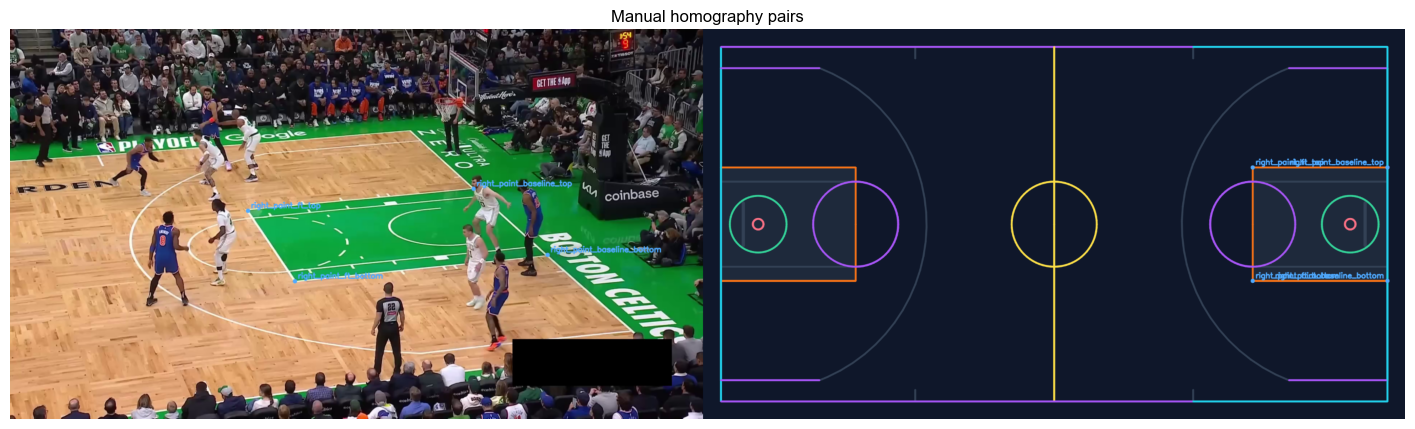

homography pairs: 4


,keypoint_name,camera_xy,bev_xy
0,right_paint_ft_top,"[659.0, 503.0]","[1550.06, 389.9]"
1,right_paint_ft_bottom,"[789.0, 698.0]","[1550.06, 710.1]"
2,right_paint_baseline_bottom,"[1489.0, 625.0]","[1930.0, 710.1]"
3,right_paint_baseline_top,"[1284.0, 442.0]","[1930.0, 389.9]"


In [4]:
# Step 2: estimate homography from the correspondence JSON.
# Run the defaults first, check the output, then change one parameter at a time.
raw_pair_data = json.loads(HOMOGRAPHY_PAIR_JSON)
pairs = []
for raw_pair in raw_pair_data["pairs"]:
    keypoint_name = str(raw_pair["keypoint_name"])
    if "bev_xy" in raw_pair:
        bev_xy = [float(v) for v in raw_pair["bev_xy"]]
    else:
        if keypoint_name not in bev_lookup:
            raise KeyError(f"BEV keypoint not found: {keypoint_name}")
        bev_xy = [float(v) for v in bev_lookup[keypoint_name]]
    pairs.append(
        {
            "keypoint_name": keypoint_name,
            "camera_xy": [float(v) for v in raw_pair["camera_xy"]],
            "bev_xy": bev_xy,
        }
    )

camera_points = np.asarray([pair["camera_xy"] for pair in pairs], dtype=np.float32)
bev_points = np.asarray([pair["bev_xy"] for pair in pairs], dtype=np.float32)
H, _ = cv2.findHomography(camera_points, bev_points, method=0)
if H is None:
    raise RuntimeError("cv2.findHomography failed. Check the point coordinates.")

homography_labels = [pair["keypoint_name"] for pair in pairs]
frame_points_vis = draw_points(frame, camera_points, homography_labels, color=(80, 170, 255), radius=6)
bev_points_vis = draw_points(bev.copy(), bev_points, homography_labels, color=(80, 170, 255), radius=6)
show_image(side_by_side(frame_points_vis, bev_points_vis, max_width=2800), "Manual homography pairs", figsize=(18, 8))
print("homography pairs:", len(pairs))
pd.DataFrame(pairs)


## Step 3 | Detect Player Boxes
First locate the players. Inspect detection separately before projecting: YOLO boxes are the starting point for all subsequent position estimates.


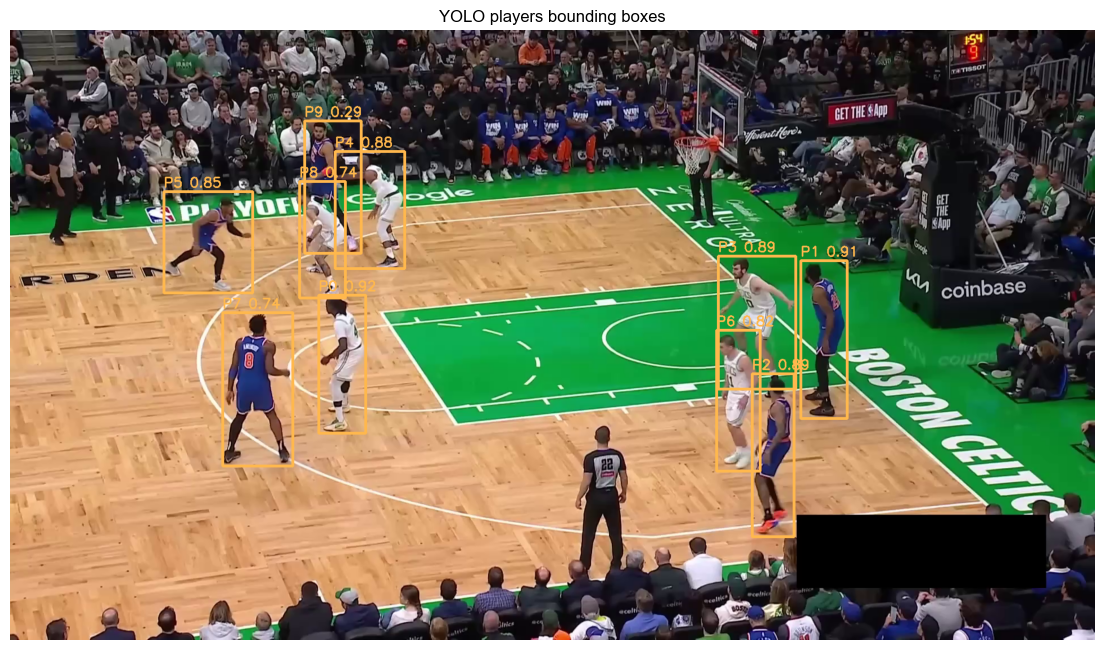

players: 10


,class_name,confidence,bbox_xyxy
0,player,0.919140,"[545.9943237304688, 469.82147216796875, 629.22..."
1,player,0.908268,"[1399.0113525390625, 408.540771484375, 1480.69..."
2,player,0.891586,"[1313.446044921875, 609.4376220703125, 1386.89..."
3,player,0.889064,"[1253.3232421875, 400.6508483886719, 1390.0167..."
4,player,0.878671,"[574.9088134765625, 216.37481689453125, 698.33..."
5,player,0.853224,"[272.2248229980469, 287.2244873046875, 429.245..."
6,player,0.822926,"[1249.996337890625, 532.0654296875, 1326.50891..."
7,player,0.743617,"[375.7243957519531, 500.896240234375, 500.2992..."
8,player,0.740695,"[511.91949462890625, 268.8858947753906, 592.66..."
9,player,0.287531,"[520.9476318359375, 162.3443145751953, 621.173..."


In [5]:
# Step 3: detect player boxes before projection.
# Run the defaults first, check the output, then change one parameter at a time.
detector = YOLO(str(DETECTOR_PATH))
det_result = detector.predict(frame, conf=0.25, imgsz=960, verbose=False)[0]

players = []
boxes = det_result.boxes
names = det_result.names or {}
if boxes is not None:
    for i in range(len(boxes)):
        box = boxes[i]
        class_id = int(box.cls[0].item())
        class_name = str(names.get(class_id, class_id))
        if class_name not in PLAYER_CLASS_NAMES:
            continue
        players.append(
            {
                "class_name": class_name,
                "confidence": float(box.conf[0].item()),
                "bbox_xyxy": [float(v) for v in box.xyxy[0].tolist()],
            }
        )

if not players:
    raise RuntimeError("No player detected in this frame. Adjust conf or select another image.")

bboxes = [player["bbox_xyxy"] for player in players]
labels = [f"P{idx} {player['confidence']:.2f}" for idx, player in enumerate(players)]
frame_det_vis = draw_boxes(frame.copy(), bboxes, labels, color=(255, 184, 77), thickness=4)
show_image(frame_det_vis, "YOLO players bounding boxes", figsize=(14, 8))
print("players:", len(players))
pd.DataFrame(players)


## Step 4 | Calculate Footpoints from Boxes
Take each box's bottom-center as an approximation of the player's ground-contact point. Understand where this point comes from before examining BEV projection.


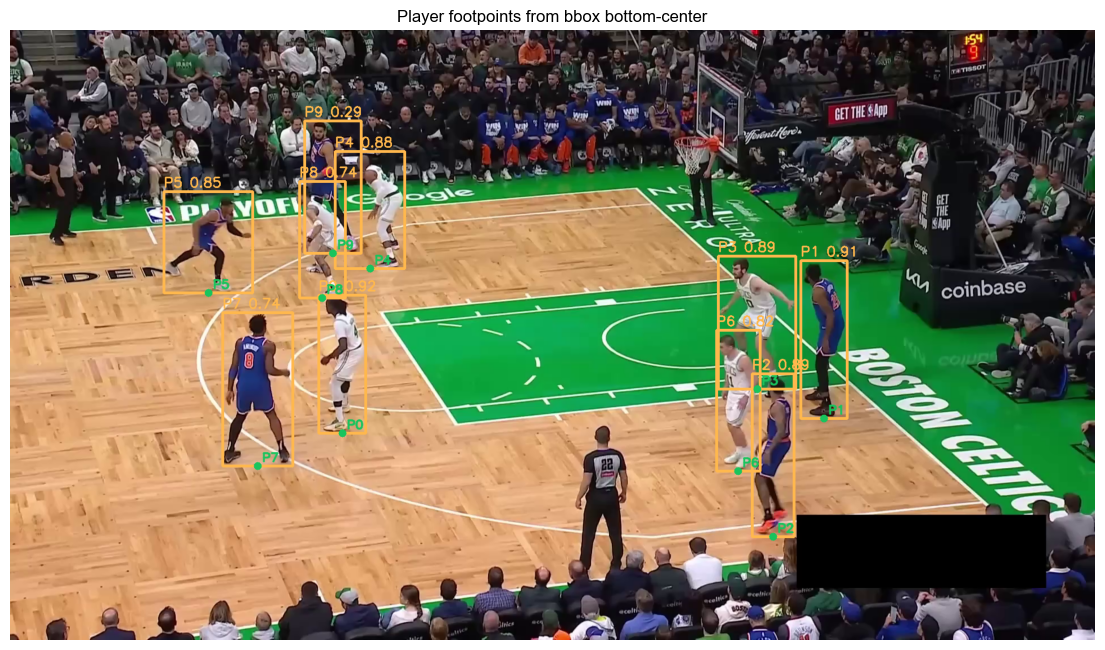

,index,class_name,confidence,foot_x,foot_y
0,0,player,0.919140,587.607361,714.278870
1,1,player,0.908268,1439.853821,688.250732
2,2,player,0.891586,1350.171814,896.847778
3,3,player,0.889064,1321.669983,635.850220
4,4,player,0.878671,636.622772,422.968506
5,5,player,0.853224,350.734924,466.061646
6,6,player,0.822926,1288.252625,780.534546
7,7,player,0.743617,438.011810,771.876831
8,8,player,0.740695,552.292084,474.642242
9,9,player,0.287531,571.060730,395.940063


In [6]:
# Step 4: take the bottom-center of each box as its footpoint.
# Run the defaults first, check the output, then change one parameter at a time.
feet = [bottom_center(bbox) for bbox in bboxes]
point_labels = [f"P{idx}" for idx in range(len(players))]

frame_feet_vis = draw_boxes(frame.copy(), bboxes, labels, color=(255, 184, 77), thickness=4)
frame_feet_vis = draw_points(frame_feet_vis, feet, point_labels, color=(24, 196, 93), radius=7)
show_image(frame_feet_vis, "Player footpoints from bbox bottom-center", figsize=(14, 8))

foot_rows = []
for idx, (player, foot) in enumerate(zip(players, feet)):
    foot_rows.append(
        {
            "index": idx,
            "class_name": player["class_name"],
            "confidence": player["confidence"],
            "foot_x": float(foot[0]),
            "foot_y": float(foot[1]),
        }
    )

pd.DataFrame(foot_rows)


## Step 5 | Project Footpoints onto BEV and Export
Use `cv2.perspectiveTransform()` to map each footpoint onto the court plane. The preview combines manual correspondences, player boxes, footpoints and BEV projections.


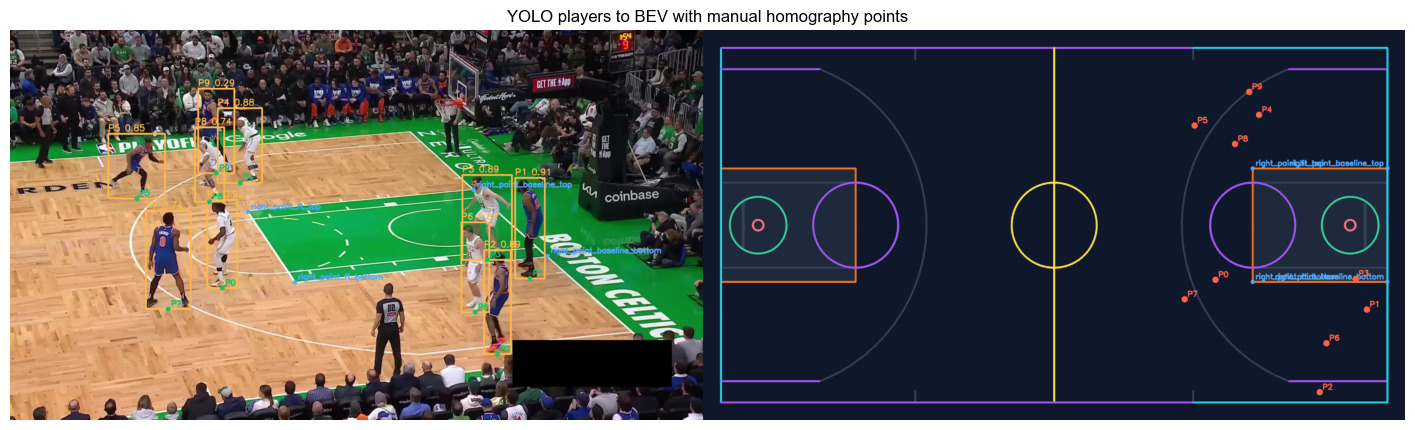

saved preview: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/results/d2_02_yolo_players_to_bev.png
saved json: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/results/d2_02_yolo_players_to_bev.json


,index,class_name,confidence,bbox_xyxy,foot_x,foot_y,bev_x,bev_y
0,0,player,0.919140,"[545.9943237304688, 469.82147216796875, 629.22...",587.607361,714.278870,1445.176392,703.692871
1,1,player,0.908268,"[1399.0113525390625, 408.540771484375, 1480.69...",1439.853821,688.250732,1872.357056,788.326111
2,2,player,0.891586,"[1313.446044921875, 609.4376220703125, 1386.89...",1350.171814,896.847778,1738.761719,1021.130127
3,3,player,0.889064,"[1253.3232421875, 400.6508483886719, 1390.0167...",1321.669983,635.850220,1840.912842,700.921936
4,4,player,0.878671,"[574.9088134765625, 216.37481689453125, 698.33...",636.622772,422.968506,1568.325928,239.227493
5,5,player,0.853224,"[272.2248229980469, 287.2244873046875, 429.245...",350.734924,466.061646,1386.060669,269.453461
6,6,player,0.822926,"[1249.996337890625, 532.0654296875, 1326.50891...",1288.252625,780.534546,1758.018555,883.057800
7,7,player,0.743617,"[375.7243957519531, 500.896240234375, 500.2992...",438.011810,771.876831,1357.725830,759.266296
8,8,player,0.740695,"[511.91949462890625, 268.8858947753906, 592.66...",552.292084,474.642242,1499.887085,321.040070
9,9,player,0.287531,"[520.9476318359375, 162.3443145751953, 621.173...",571.060730,395.940063,1540.091064,173.611771


In [7]:
# Step 5: project footpoints onto BEV and export the results.
# Run the defaults first, check the output, then change one parameter at a time.
pts = np.asarray(feet, dtype=np.float32).reshape(-1, 1, 2)
bev_feet = cv2.perspectiveTransform(pts, H).reshape(-1, 2)

frame_base = draw_points(frame, camera_points, homography_labels, color=(80, 170, 255), radius=6)
frame_vis = draw_boxes(frame_base, bboxes, labels, color=(255, 184, 77), thickness=4)
frame_vis = draw_points(frame_vis, feet, point_labels, color=(24, 196, 93), radius=7)
bev_base = draw_points(bev.copy(), bev_points, homography_labels, color=(80, 170, 255), radius=6)
bev_vis = draw_points(bev_base, bev_feet, point_labels, color=(255, 99, 72), radius=9)
preview = side_by_side(frame_vis, bev_vis, max_width=2800)
show_image(preview, "YOLO players to BEV with manual homography points", figsize=(18, 8))

out_path = COURSE_ROOT / "assets" / "results" / "d2_02_yolo_players_to_bev.png"
out_json = COURSE_ROOT / "assets" / "results" / "d2_02_yolo_players_to_bev.json"
rows = []
for idx, (player, foot, bev_foot) in enumerate(zip(players, feet, bev_feet)):
    rows.append(
        {
            "index": idx,
            **player,
            "foot_x": float(foot[0]),
            "foot_y": float(foot[1]),
            "bev_x": float(bev_foot[0]),
            "bev_y": float(bev_foot[1]),
        }
    )

save_image_rgb(out_path, preview)
save_json({"homography_pairs": pairs, "players": rows}, out_json)
print("saved preview:", out_path)
print("saved json:", out_json)
pd.DataFrame(rows)


## Output Files

- `assets/results/d2_02_yolo_players_to_bev.png`: player footpoints projected onto BEV.
- `assets/results/d2_02_yolo_players_to_bev.json`: manual correspondences and projected player footpoints.
